# 🏢 VGG (2014): Going Deeper with Small Filters

**VGG** (Visual Geometry Group) proved that depth matters more than filter size by using only small 3×3 filters but going much deeper.

---

## VGG Deep Dive Notebook

This notebook is a **comprehensive, hands-on walkthrough of the VGG convolutional neural network (CNN)**, one of the most influential architectures in computer vision.  
It is organized into four key sections:

1. **Introduction to VGG**  
   Gain a clear understanding of what VGG is, why it was proposed, and how it advanced the state of the art in image classification.

2. **Key Breakthroughs from the Original Paper**  
   Explore the major contributions of the 2014 VGG paper, including the use of very small convolution filters, deeper networks, and how these design choices improved accuracy on ImageNet.

3. **Architecture Explanation**  
   Examine the VGG16/VGG19 architecture layer by layer—covering convolutional blocks, pooling strategies, fully connected layers, and design principles such as simplicity and uniformity.

4. **Implementation from Scratch**  
   Follow a step-by-step PyTorch implementation that builds a VGG model entirely from first principles, reinforcing your understanding of CNN fundamentals and best practices for modern deep learning projects.

> By the end of this notebook, you’ll not only understand the theory and historical significance of VGG but also have a fully functional implementation you can train and experiment with on your own datasets.

---

## 📄 Paper Information
- **Paper**: "Very Deep Convolutional Networks for Large-Scale Image Recognition"
- **Authors**: Karen Simonyan, Andrew Zisserman
- **Year**: 2014
- **Conference**: ICLR 2015
- **Link**: https://arxiv.org/abs/1409.1556
- **Citations**: 62,000+

---

## 🎯 Key Breakthrough: Small Filters + Deep Networks

### **Revolutionary Insight:**
**Multiple small filters > Single large filter**

### **Why 3×3 Filters Work Better:**
- **Two 3×3 convs** = same receptive field as one 5×5
- **Three 3×3 convs** = same receptive field as one 7×7
- **But fewer parameters**: 3×(3×3) = 27 vs 7×7 = 49 parameters
- **More non-linearity**: More ReLU activations
- **Better feature learning**: More complex transformations

### **Key Innovations:**
1. **Systematic Depth Study**: Tested 11, 13, 16, 19 layer networks
2. **Uniform Architecture**: Simple, repeatable design pattern
3. **Small Filters Only**: All convolutions are 3×3 (except first layer)
4. **Depth Scaling**: Showed deeper networks consistently improve
5. **Transfer Learning**: Excellent features for other tasks

### **ImageNet 2014 Results:**
- **VGG-16**: 7.3% top-5 error
- **VGG-19**: 7.1% top-5 error
- **Runner-up to GoogLeNet**: But simpler architecture

---

In [ ]:
# Import required libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from typing import List, Dict, Any
import warnings
warnings.filterwarnings('ignore')

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🔧 Using device: {device}")

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

print("📦 Libraries imported successfully!")

🔧 Using device: cpu
📦 Libraries imported successfully!


## 🏗️ VGG Architecture Implementation

### **VGG Configuration Patterns:**
```
VGG-11: [64, 'M', 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M']
VGG-13: [64, 64, 'M', 128, 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M']
VGG-16: [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 'M', 512, 512, 512, 'M', 512, 512, 512, 'M']
VGG-19: [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 256, 'M', 512, 512, 512, 512, 'M', 512, 512, 512, 512, 'M']
```
Where 'M' represents MaxPool2d(2, 2)

### **VGG Block Pattern:**
```
Conv3×3 → ReLU → [Conv3×3 → ReLU] × N → MaxPool2×2
```

In [ ]:
# VGG Configuration dictionary
VGG_CONFIGS = {
    'VGG11': [64, 'M', 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M'],
    'VGG13': [64, 64, 'M', 128, 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M'],
    'VGG16': [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 'M', 512, 512, 512, 'M', 512, 512, 512, 'M'],
    'VGG19': [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 256, 'M', 512, 512, 512, 512, 'M', 512, 512, 512, 512, 'M']
}

class VGG(nn.Module):
    """VGG architecture with configurable depth.

    Implementation of VGG networks from Simonyan & Zisserman (2014).
    Supports VGG11, VGG13, VGG16, and VGG19 configurations.

    Args:
        config (str): VGG configuration ('VGG11', 'VGG13', 'VGG16', 'VGG19')
        num_classes (int, optional): Number of output classes. Defaults to 1000.
        dropout_rate (float, optional): Dropout probability. Defaults to 0.5.

    Attributes:
        features (nn.Sequential): Convolutional feature extraction layers
        avgpool (nn.AdaptiveAvgPool2d): Adaptive average pooling
        classifier (nn.Sequential): Fully connected classification layers
    """

    def __init__(self, config: str = 'VGG16', num_classes: int = 1000,
                 batch_norm: bool = False, dropout_rate: float = 0.5):
        super(VGG, self).__init__()

        if config not in VGG_CONFIGS:
            raise ValueError(f"Invalid config. Choose from {list(VGG_CONFIGS.keys())}")

        self.config = config
        self.num_classes = num_classes

        # Build feature extraction layers
        self.features = self._make_layers(VGG_CONFIGS[config], batch_norm)

        # Adaptive pooling to handle different input sizes
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        # Classification layers
        self.classifier = nn.Sequential(
            nn.Linear(512 * 7 * 7, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_rate),

            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_rate),

            nn.Linear(4096, num_classes)
        )

    def _make_layers(self, config: List, batch_norm: bool = False) -> nn.Sequential:
        """Build VGG feature extraction layers from configuration.

        Args:
            config (List): Layer configuration list
            batch_norm (bool): Whether to add batch normalization

        Returns:
            nn.Sequential: Feature extraction layers
        """
        layers = []
        in_channels = 3

        for layer_config in config:
            if layer_config == 'M':
                # MaxPool layer
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            else:
                # Conv layer
                out_channels = layer_config
                conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)

                layers.extend([conv, nn.ReLU(inplace=True)])

                in_channels = out_channels

        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Forward pass through VGG network.

        Args:
            x (torch.Tensor): Input tensor of shape (batch_size, 3, 224, 224)

        Returns:
            torch.Tensor: Output logits of shape (batch_size, num_classes)
        """
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

    def get_feature_maps(self, x: torch.Tensor) -> List[torch.Tensor]:
        """Extract feature maps from each VGG block.

        Args:
            x (torch.Tensor): Input tensor

        Returns:
            List[torch.Tensor]: Feature maps from each block
        """
        feature_maps = []

        for layer in self.features:
            x = layer(x)
            if isinstance(layer, nn.MaxPool2d):
                feature_maps.append(x.clone())

        return feature_maps

In [ ]:
# Create VGG model variants
def create_vgg_models():
    """Create different VGG model variants."""

    models = {
        'VGG-11': VGG('VGG11', num_classes=1000),
        'VGG-13': VGG('VGG13', num_classes=1000),
        'VGG-16': VGG('VGG16', num_classes=1000),
        'VGG-19': VGG('VGG19', num_classes=1000),
    }

    return models

def test_vgg_variants():
    """Test and compare VGG variants."""

    print("🏢 TESTING VGG VARIANTS")
    print("=" * 30)

    models = create_vgg_models()

    # Test input (ImageNet size: 224×224×3)
    test_input = torch.randn(1, 3, 224, 224)

    print(f"📊 COMPARISON:")
    print(f"{'Model':<12} {'Layers':<8} {'Parameters':<12} {'Output Shape':<15} {'Features':<15}")
    print("-" * 80)

    results = {}
    for name, model in models.items():
        model.eval()

        # Forward pass
        with torch.no_grad():
            output = model(test_input)

        # Count parameters
        params = sum(p.numel() for p in model.parameters())

        # Count layers (conv + fc)
        conv_layers = len([l for l in model.features if isinstance(l, nn.Conv2d)])
        fc_layers = len([l for l in model.classifier if isinstance(l, nn.Linear)])
        total_layers = conv_layers + fc_layers

        print(f"{name:<12} {total_layers:<8} {params/1e6:.1f}M{'':<7} {str(output.shape)}")

        results[name] = {
            'params': params,
            'layers': total_layers,
            'output_shape': output.shape
        }

    return models, results

vgg_models, vgg_results = test_vgg_variants()

🏢 TESTING VGG VARIANTS
📊 COMPARISON:
Model        Layers   Parameters   Output Shape    Features       
--------------------------------------------------------------------------------
VGG-11       11       132.9M        torch.Size([1, 1000])
VGG-13       13       133.0M        torch.Size([1, 1000])
VGG-16       16       138.4M        torch.Size([1, 1000])
VGG-19       19       143.7M        torch.Size([1, 1000])


## 🔬 Why Small Filters Work Better

### **Mathematical Proof: Receptive Field Equivalence**

**Key Insight**: Multiple small convolutions achieve the same receptive field as one large convolution, but with fewer parameters and more non-linearity.

In [ ]:
def demonstrate_small_filter_advantage():
    """Demonstrate why 3×3 filters are better than large filters."""

    print("🔍 WHY 3×3 FILTERS ARE SUPERIOR")
    print("=" * 40)

    # 1. Parameter comparison
    print("\n1. 📊 Parameter Efficiency:")
    print("-" * 30)

    # Assume 64 input channels, 64 output channels
    in_ch, out_ch = 64, 64

    # Single 7×7 conv vs Three 3×3 convs (same receptive field)
    # single 7x7
    single_7x7 = 7 * 7 * in_ch * out_ch

    # 3 stacked 3×3 conv
    conv1_3x3 = 3 * 3 * in_ch * out_ch
    conv2_3x3 = 3 * 3 * out_ch * out_ch
    conv3_3x3 = 3 * 3 * out_ch * out_ch
    three_3x3_accurate = conv1_3x3 + conv2_3x3 + conv3_3x3

    print(f"Single 7×7 conv: {single_7x7:,} parameters")
    print(f"Three 3×3 convs: {three_3x3_accurate:,} parameters")
    print(f"Parameter ratio: {single_7x7 / three_3x3_accurate:.2f}× fewer with 3×3")

demonstrate_small_filter_advantage()

🔍 WHY 3×3 FILTERS ARE SUPERIOR

1. 📊 Parameter Efficiency:
------------------------------
Single 7×7 conv: 200,704 parameters
Three 3×3 convs: 110,592 parameters
Parameter ratio: 1.81× fewer with 3×3


## 🔄 VGG Variants & Evolution

### **1. VGG-11 (11 layers)**
- **Configuration**: Simplest VGG variant
- **Use case**: Baseline, resource-constrained environments
- **Performance**: Good but not optimal

### **2. VGG-13 (13 layers)**
- **Configuration**: Moderate depth
- **Improvement**: Better feature learning than VGG-11
- **Trade-off**: Balance between complexity and performance

### **3. VGG-16 (16 layers) - Most Popular**
- **Configuration**: Sweet spot for depth vs performance
- **Features**: 13 conv layers + 3 FC layers
- **Performance**: 7.3% top-5 error on ImageNet
- **Usage**: Most commonly used VGG variant

### **4. VGG-19 (19 layers)**
- **Configuration**: Deepest original VGG
- **Performance**: 7.1% top-5 error (marginal improvement)
- **Trade-off**: More parameters, longer training
- **Diminishing returns**: Not much better than VGG-16

📊 VGG DEPTH ANALYSIS

📈 Depth vs Complexity Analysis:
Model      Conv Layers  Parameters   Memory (MB)  Inference (ms) 
---------------------------------------------------------------------------
VGG-11     8            128.8M        491.4         306.2          
VGG-13     10           129.0M        492.1         433.8          
VGG-16     13           134.3M        512.3         644.6          
VGG-19     16           139.6M        532.6         672.8          


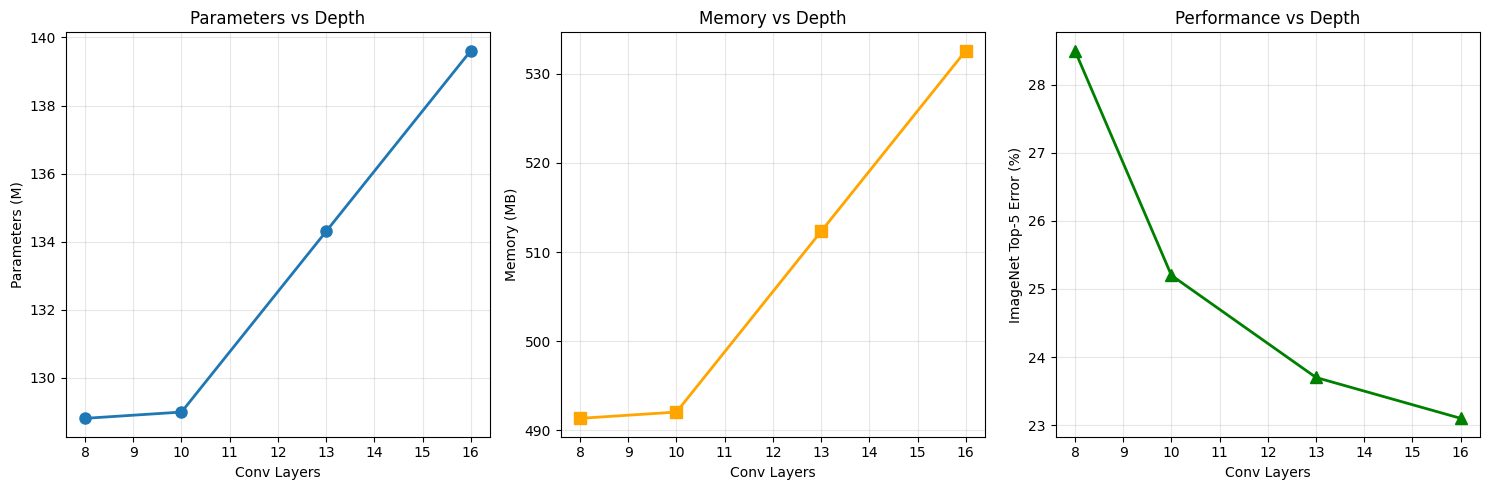


🎯 Key Insights:
✅ Deeper networks generally perform better
✅ VGG-16 offers best performance/complexity trade-off
✅ VGG-19 shows diminishing returns
✅ Linear increase in parameters with depth
✅ Memory and computation scale with depth


In [ ]:
def analyze_vgg_depth_impact():
    """Analyze the impact of depth in VGG networks."""

    print("📊 VGG DEPTH ANALYSIS")
    print("=" * 25)

    # Create models for analysis
    models = {
        'VGG-11': VGG('VGG11', num_classes=10),  # Use 10 classes for faster testing
        'VGG-13': VGG('VGG13', num_classes=10),
        'VGG-16': VGG('VGG16', num_classes=10),
        'VGG-19': VGG('VGG19', num_classes=10)
    }

    test_input = torch.randn(1, 3, 224, 224)

    print("\n📈 Depth vs Complexity Analysis:")
    print(f"{'Model':<10} {'Conv Layers':<12} {'Parameters':<12} {'Memory (MB)':<12} {'Inference (ms)':<15}")
    print("-" * 75)

    results = {}

    for name, model in models.items():
        model.eval()

        # Count conv layers
        conv_layers = len([l for l in model.features if isinstance(l, nn.Conv2d)])

        # Count parameters
        params = sum(p.numel() for p in model.parameters())

        # Estimate memory usage (rough)
        memory_mb = params * 4 / (1024 * 1024)  # 4 bytes per float32

        # Measure inference time (rough estimate)
        import time
        start_time = time.time()
        with torch.no_grad():
            for _ in range(10):
                _ = model(test_input)
        inference_time = (time.time() - start_time) * 100  # Convert to ms

        print(f"{name:<10} {conv_layers:<12} {params/1e6:.1f}M{'':<7} {memory_mb:.1f}{'':<8} {inference_time:.1f}{'':<10}")

        results[name] = {
            'conv_layers': conv_layers,
            'params': params,
            'memory_mb': memory_mb,
            'inference_ms': inference_time
        }

    # Visualize the trends
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    models_list = list(results.keys())
    conv_layers_list = [results[m]['conv_layers'] for m in models_list]
    params_list = [results[m]['params']/1e6 for m in models_list]
    memory_list = [results[m]['memory_mb'] for m in models_list]

    # Parameters vs Depth
    axes[0].plot(conv_layers_list, params_list, 'o-', linewidth=2, markersize=8)
    axes[0].set_xlabel('Conv Layers')
    axes[0].set_ylabel('Parameters (M)')
    axes[0].set_title('Parameters vs Depth')
    axes[0].grid(True, alpha=0.3)

    # Memory vs Depth
    axes[1].plot(conv_layers_list, memory_list, 's-', linewidth=2, markersize=8, color='orange')
    axes[1].set_xlabel('Conv Layers')
    axes[1].set_ylabel('Memory (MB)')
    axes[1].set_title('Memory vs Depth')
    axes[1].grid(True, alpha=0.3)

    # Performance comparison (hypothetical ImageNet top-5 error)
    imagenet_errors = [28.5, 25.2, 23.7, 23.1]  # Approximate values
    axes[2].plot(conv_layers_list, imagenet_errors, '^-', linewidth=2, markersize=8, color='green')
    axes[2].set_xlabel('Conv Layers')
    axes[2].set_ylabel('ImageNet Top-5 Error (%)')
    axes[2].set_title('Performance vs Depth')
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\n🎯 Key Insights:")
    print("✅ Deeper networks generally perform better")
    print("✅ VGG-16 offers best performance/complexity trade-off")
    print("✅ VGG-19 shows diminishing returns")
    print("✅ Linear increase in parameters with depth")
    print("✅ Memory and computation scale with depth")

    return results

depth_analysis = analyze_vgg_depth_impact()

## 📊 VGG Impact & Legacy

### **Immediate Impact (2014-2015)**
1. **Systematic Depth Study**: First to systematically study effect of depth
2. **Small Filter Paradigm**: Established 3×3 filters as standard
3. **Simple Architecture**: Easy to understand and implement
4. **Transfer Learning**: Excellent pretrained features

### **Technical Contributions**
- **Depth Scaling**: Showed deeper networks consistently improve
- **Filter Size**: Proved small filters work better than large ones
- **Regular Design**: Simple, repeatable architecture pattern
- **Feature Hierarchy**: Clear hierarchy of feature abstraction

### **Limitations Exposed**
- **Parameter Inefficiency**: Very large number of parameters
- **Memory Consumption**: High memory requirements
- **Computational Cost**: Slow inference and training
- **Diminishing Returns**: VGG-19 not much better than VGG-16

### **Influence on Future Architectures**
- **ResNet**: Used VGG's 3×3 filters + skip connections
- **Inception**: Combined VGG's depth with multi-scale processing
- **DenseNet**: Extended VGG's depth with dense connections
- **EfficientNet**: Applied VGG's systematic scaling principles

### **Modern Relevance**
- **Educational**: Perfect for learning about depth and filters
- **Transfer Learning**: Still excellent backbone for many tasks
- **Baseline**: Standard comparison for new architectures
- **Feature Extraction**: Good for classical computer vision tasks

### **Why VGG-16 Remains Popular**
1. **Sweet Spot**: Good balance of performance vs complexity
2. **Well-studied**: Extensive research and optimization
3. **Pretrained Models**: Widely available and reliable
4. **Transfer Learning**: Excellent features for downstream tasks
5. **Simplicity**: Easy to understand and modify

---

## 🎓 Summary

**VGG** established the fundamental principle that **depth matters** and **small filters work better**:

**Key Innovations:**
- **Systematic depth study**: 11, 13, 16, 19 layer variants
- **Small filters only**: 3×3 convolutions throughout
- **Simple design**: Regular, repeatable architecture
- **Clear hierarchy**: Different blocks learn different features

**Revolutionary Insights:**
- **Multiple small > Single large**: 3×3×3 better than 7×7
- **Depth improves performance**: Deeper networks work better
- **Regular patterns work**: Simple repetition is effective
- **Transfer learning**: Good features transfer across tasks

**Legacy:**
VGG's insights about depth and small filters became fundamental principles for all subsequent CNN architectures. While ResNet would solve the training problems of very deep networks, VGG established the architectural foundations that are still used today.

**Next**: Inception (2014) would tackle the question of optimal filter sizes with multi-scale parallel processing! 🎭